# 위고비 확산이 기존 사망보험금에 미치는 영향 — 근거부터 결론까지

**공개 임상 근거 × 국내 적용 범위 × 10년 정기사망보장 모형** · 2026-11-17 · 재현 가능한 연구용 노트북

> **결론 (기준조건):** SELECT와 유사한 고위험 가상 피보험자 **1,000명**이 동일한 사망보장(1인당 1억 원)을 가지고 있고, 연 최초 치료 시작확률이 **1%→3%**로 달라지는 경우, 10년간 기대 사망은 **약 1.13건**, 사망보험금 현재가치는 **약 9,696만 원 감소**한다. 
>
> **무효과 포함 비교 범위:** 사망효과 HR=1(없음)부터 HR=0.71(SELECT 보고 구간 아래쪽)까지 **0~1.48억 원**이다. **이 범위는 국내 절감액의 95% 신뢰구간이 아니라, 다른 조건이 모두 일정한 민감도 범위**이다.
>
> **국내 해석:** 이는 **국내 보험사의 실제 절감액을 관측한 결과가 아니다.** 한국에 적용해도 될지 검토할 수 있는 가상 계약 모델이며, 시작률·36개월 효과기간은 연구 가정이다. 

**읽는 법:** ① 실제 연구에서 확인된 사실 → ② 가정 → ③ 1,000명 모형 → ④ 그래프 → ⑤ 국내 환산 → ⑥ 발표 결론 및 한계. 코드 셀은 모두 직접 실행할 수 있다.

## 1. 우리가 풀 질문 — 모형 밖의 이야기는 하지 않는다

**질문:** 똑같은 기존 사망보험 가입자에게 위고비 치료가 더 확산된다면, 보험사가 **앞으로 지급할 것으로 예상하는 사망보험금**이 어떻게 달라질까?

- **사망 시 지급하는 약정 보험금은 1억 원 그대로**다.
- 달라지는 것은 사망할 가능성과 시점이므로 **평균적으로 예상되는 지출**이다.
- 처음 가입한 사람은 모두 치료 미시작자이다. **치료 시작확률은 미시작·생존자를 분모로 매월 갱신**한다.
- 연 1%→3%는 **확산 비교**이지, 약제비 특약 도입 효과인 B가 아니다. 둘을 혼동하면 잘못된 수익성 분석이 된다.

**한 줄 원리:** 치료 시작 증가 → 일부 피보험자의 사망위험 감소 → 계약기간 내 기대 사망 감소 → 기대 보험금 현재가치 감소.

### 1-1. 전체 분석 흐름 그림

In [1]:
from IPython.display import display, Image
from pathlib import Path
from PIL import Image as PILImage
# 그림은 노트북에서 수식·데이터로 다시 그리며, 별도 파일이 없어도 재현됩니다.

## 2. 실제 연구가 확인한 것과 확인하지 못한 것

| 자료 | 논문·기관에서 관측하거나 발표한 내용 | 이번 모형에 사용하는 이유 | 반드시 남기는 한계 |
|---|---|---|---|
| [SELECT 임상시험(2023)](https://doi.org/10.1056/NEJMoa2307563) | ≥45세·BMI≥27·기존 심혈관질환·비당뇨, 전체 사망 HR **0.81**, 보고된 95% CI **0.71~0.93**; 평균 추적 **39.8개월** | 치료효과·대상 범위 | 전체 사망은 위계검정상 **탐색적** 결과. 국내 전체 인구·10년 효과로 바로 이전 불가 |
| [SELECT 검토자료 Table 19](https://www.ncbi.nlm.nih.gov/books/NBK619926/table/tr8269868382084182_ch01_t19/?report=objectonly) | 위약군 **458건·29,112인년**, 치료군 **375건·29,283인년** | 기초 사망강도(위약군) 계산 | 기간 평균 발생률 ≠ 개인 연령별 위험. 치료군 사망률을 다시 HR과 중복 적용하지 않음 |
| [Nanna 등(2025)](https://pmc.ncbi.nlm.nih.gov/articles/PMC12046440/) | 미국 NHANES×위험예측모형×SELECT 효과의 10년 장기 추계 | *임상시험 → 인구 규모 → 장기 사건 수*의 **방법론적 선례** | 미국인·SMART2 위험 사용, 10년 치료효과 등 가정. **Nanna 예측수치를 본 모델 입력값으로 쓰지 않음** |
| [CBO(2024)](https://www.cbo.gov/publication/60816) | 미국 Medicare의 AOM 보장확대 시 신규 적격자의 연간 시작 **3~5% 예측** | 3% 조건을 설명할 때 **외부 비교 참고** | 국내 고위험 위고비 전용 실측치가 아님. 1% 기본값은 CBO가 입증하지 않음 |
| [국민건강영양조사 2024](https://knhanes.kdca.go.kr/) | 연구팀의 SELECT 유사 대리집단 재집계 | 1,000명 결과를 국내 가상 10만명에 **조건부 환산** | 유사 조건 해당 표본 11명, 보험가입·위고비 이력 미관측 |
| [국가데이터처 2024 완전생명표](https://mods.go.kr/board.es?act=view&bid=208&list_no=439533&mid=a10301010000) | 국내 일반인구 연령별 사망확률 | 서로 다른 사망률의 의미 구분 | 일반인구 사망률을 SELECT 고위험군에 대신 쓰지 않음 |

**확인 범위:** 공개 논문·기관 자료를 대조했다. 국내 원자료 `HN24_ALL.sav`의 **이번 실행에 의한 독립 재집계는 수행하지 않는다.** 국내 유사집단 비율은 기존 제공된 재집계 수치를 재사용한다.

### 2-1. 왜 사망 건수와 HR이 다른가?

- **사망 건수:** 임상시험 기간에 실제로 사망한 인원.
- **인년(person-year):** 각 피험자가 관찰된 시간을 합친 단위. 1명이 2년 관찰되면 2인년.
- **연간 평균 사망발생률:** 사망 건수 ÷ 관찰 인년. 바로 연간 사망확률이 아님.
- **사망력(hazard)·위험비(HR):** 아직 살아 있는 사람의 매우 짧은 순간의 사망위험을 비교. HR 0.81은 순간 사망강도의 상대값을 나타낸다.

**이번 계산의 유일한 기초 사망력:** 위약군의 관찰된 평균 사망발생률을 **일정한 사망강도**로 근사한다. 이것은 분명한 모형 가정이다.

$$
\mu_0=\frac{458\;\mathrm{건}}{29{,}112\;\mathrm{인년}}\approx 0.01573\;\mathrm{년}^{-1}
$$

$$
P(\mathrm{한\ 달\ 이내\ 사망})=1-e^{-\mu_0/12}
$$

**왜 지수를 쓰나?** 한 달 내내 살아 있을 확률은 아주 작은 구간들의 생존확률을 계속 곱한 값이다. 이를 지수식으로 나타내면 사망확률은 `1−생존확률`이 된다. **HR은 사망력에 곱하고, 연 사망확률에 직접 곱하지 않는다.**

In [2]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from matplotlib import font_manager

fontset={f.name for f in font_manager.fontManager.ttflist}
for ff in ['Arial Unicode MS','AppleGothic','NanumSquare','Noto Sans CJK KR','Malgun Gothic','NanumGothic']:
    if ff in fontset:
        plt.rcParams['font.family']=ff
        break
plt.rcParams.update({'axes.unicode_minus':False,'axes.spines.top':False,'axes.spines.right':False,'axes.titlesize':13,'font.size':10})
BLUE='#2563A6'; GREEN='#0B8A7A'; GREY='#66778E'; ORANGE='#D47A31'

# 관측/논문값과 연구자 설정을 구분
SELECT_PLACEBO_DEATHS=458
SELECT_PLACEBO_PERSON_YEARS=29112
MU=SELECT_PLACEBO_DEATHS/SELECT_PLACEBO_PERSON_YEARS # 평균 발생률의 일정 사망강도 근사
TRIAL_HR=0.81 # SELECT 탐색적, 한국에서 효과를 검증한 값 아님
COHORT=1000 # SELECT 유사 기존 가입자의 가상 인원
BENEFIT=100_000_000 # 원/사망, 가상 계약
TERM=10 # 년
ANNUAL_DISCOUNT=0.03 # 가상 계약 평가 이율
EFFECT_MONTHS=36 # 시작 후 효과 창, 과학적으로 확정된 약효 만료일 아님
LOW_START=.01 # 국내 실증 시작률 아님
HIGH_START=.03 # 국내 실증 시작률 아님

print('위약군 평균 연 사망강도:', round(MU,8),'(년^-1)')
print('일정강도 가정의 연 사망확률:',round((1-math.exp(-MU))*100,4),'%')
print('치료 시작 전의 한 달 사망확률:',round((1-math.exp(-MU/12))*100,4),'%')
print('치료효과 적용 중 한 달 사망확률:',round((1-math.exp(-MU*TRIAL_HR/12))*100,4),'%')

위약군 평균 연 사망강도: 0.01573234 (년^-1)
일정강도 가정의 연 사망확률: 1.5609 %
치료 시작 전의 한 달 사망확률: 0.131 %
치료효과 적용 중 한 달 사망확률: 0.1061 %


## 3. 10년의 모든 사람을 매월 추적하는 방법

가상 가입자 1,000명은 최초에 모두 **살아 있는 미시작자**다. 다음 월로 넘어갈 때마다 누구는 새로 시작하고 누구는 사망한다. 치료를 시작한 사람은 그 시작 월을 기억하므로 **3년(36개월) 효과창**을 추적할 수 있다.

1. 생존·미시작자 × 월 시작확률 → 이달의 **신규 시작자**.
2. 신규 시작자는 그 달부터 사망강도에 **HR 0.81**을 적용. 미시작자는 HR 1.
3. 각 집단에 월별 사망확률을 적용하고 **살아남은 사람만 다음 달**로 이동.
4. 매월 예상 사망자 수 × 약정 사망보험금 1억 원 → 그 달의 **기대 보험금**.
5. 미래의 1억 원은 지금과 값이 다르므로 연 3%로 **현재가치로 할인**한 뒤 120개월 합산.

**모형 수식 3개만 기억하면 충분**:

$$
p_{\mathrm{start},m}=1-(1-a)^{1/12}
$$

$$
p_{\mathrm{death},m}=1-\exp\left(-\mu_0\times HR_m/12\right)
$$

$$
PV_{\mathrm{claim}}=\sum_{m=1}^{120}\frac{E[D_m]\times 100{,}000{,}000}{1.03^{(m-0.5)/12}}
$$

- $a$: 그 달에 살아 있는 미시작자를 기준으로 한 **연환산 첫 시작확률** (연 1% 또는 3%).
- $D_m$: **m월 기대 사망 건수** (소수도 가능). $HR_m$: 시작한 지 36개월 이내에는 0.81, 그 밖에는 1.
- 시작은 월초, 사망보험금 지급은 월중앙으로 근사한다. **다른 원칙을 택하면 금액은 조금 달라질 수 있다.**

In [3]:
# 월별 생존·사망·첫 치료 시작을 직접 추적하는 함수
N_YEARS=10
DEATH_BENEFIT=BENEFIT
def project(annual_start,hr=.81,effect_m=36,mu=MU,discount=.03,cohort=1000,years=10):
    n_months=years*12
    never_started=float(cohort)
    active=[0.]*n_months
    first_start_prob= -math.expm1(math.log1p(-annual_start)/12)
    rows=[]
    total_started=0.; total_deaths=0.; total_pv=0.
    for m in range(n_months):
        survival_start=never_started + sum(active)
        new = never_started*first_start_prob
        never_started -= new
        active[m] += new
        total_started+=new
        death_never=never_started * -math.expm1(-mu/12)
        death_started=0.
        for j in range(m+1):
            age=m-j
            mult=hr if age<effect_m else 1.
            dq= -math.expm1(-mu*mult/12)
            d=active[j]*dq
            active[j]-=d
            death_started+=d
        never_started-=death_never
        monthly_death=death_never+death_started
        total_deaths+=monthly_death
        pv=monthly_death*DEATH_BENEFIT/(1+discount)**((m+.5)/12)
        total_pv+=pv
        alive_end=never_started+sum(active)
        assert abs(survival_start-(monthly_death+alive_end)) < 1e-7 * max(1,cohort)
        rows.append({'월':m+1,'연도':m//12+1,'최초_시작':new,'누적_시작':total_started,
                     '월_기대사망':monthly_death,'누적_기대사망':total_deaths,'월_보험금_현가_원':pv,
                     '누적_보험금_현가_원':total_pv,'미시작_생존':never_started,
                     '시작경험_생존':sum(active),'전체_생존':alive_end})
    d=pd.DataFrame(rows)
    return {'n':cohort,'annual_start':annual_start,'hr':hr,'duration_months':effect_m,'mu':mu,
            'discount':discount,'starts':total_started,'deaths':total_deaths,'survivors':cohort-total_deaths,
            'pv':total_pv,'nominal':total_deaths*DEATH_BENEFIT,'monthly':d}


def contrast(hr=.81,effect_m=36,mu=MU,discount=.03,low=.01,high=.03,n=1000):
    kw=dict(hr=hr,effect_m=effect_m,mu=mu,discount=discount,cohort=n)
    L=project(low,**kw);H=project(high,**kw)
    return {'low':L,'high':H,'delta_starts':H['starts']-L['starts'],
            'avoided_deaths':L['deaths']-H['deaths'],'pv_saving':L['pv']-H['pv'],
            'nominal_saving':L['nominal']-H['nominal']}

### 3-1. 코드를 실행하고 원본 계산이 일치하는지 검산

In [4]:
base=contrast()
base_table=pd.DataFrame({
    '항목':['10년 누적 첫 시작 (명)','10년 기대 사망 (건)','10년 사망보험금 명목액 (억 원)','10년 사망보험금 현가 (억 원)'],
    '저확산 연 1%':[base['low']['starts'],base['low']['deaths'],base['low']['nominal']/1e8,base['low']['pv']/1e8],
    '고확산 연 3%':[base['high']['starts'],base['high']['deaths'],base['high']['nominal']/1e8,base['high']['pv']/1e8]
})
base_table['차이(고확산-저확산)']=base_table['고확산 연 3%']-base_table['저확산 연 1%']
display(base_table.round(4))
print(f"기대 사망 감소: {base['avoided_deaths']:.4f}건")
print(f"보험금 PV 감소: {base['pv_saving']:,.0f}원 = {base['pv_saving']/1e8:.4f}억 원")
assert abs(base['pv_saving']-96961864)<5
assert abs(base['low']['deaths']-144.94)<.1
assert abs(base['high']['deaths']-143.81)<.1

,항목,저확산 연 1%,고확산 연 3%,차이(고확산-저확산)
0,10년 누적 첫 시작 (명),88.6505,244.0920,155.4416
1,10년 기대 사망 (건),144.9396,143.8117,-1.1279
2,10년 사망보험금 명목액 (억 원),144.9396,143.8117,-1.1279
3,10년 사망보험금 현가 (억 원),125.9768,125.0072,-0.9696


기대 사망 감소: 1.1279건
보험금 PV 감소: 96,961,864원 = 0.9696억 원


**표 해석:** 고확산은 시작자가 약 155명 더 많지만 **사망자가 155명 줄었다는 뜻이 아니다.** 계약이 만료되기 전 사망할 기대 인원이 약 1.13건 줄어든다는 뜻이다. 보험금액은 유지되고 지급될 확률·시점만 달라진다.

## 4. 실제 그래프로 결론을 확인한다

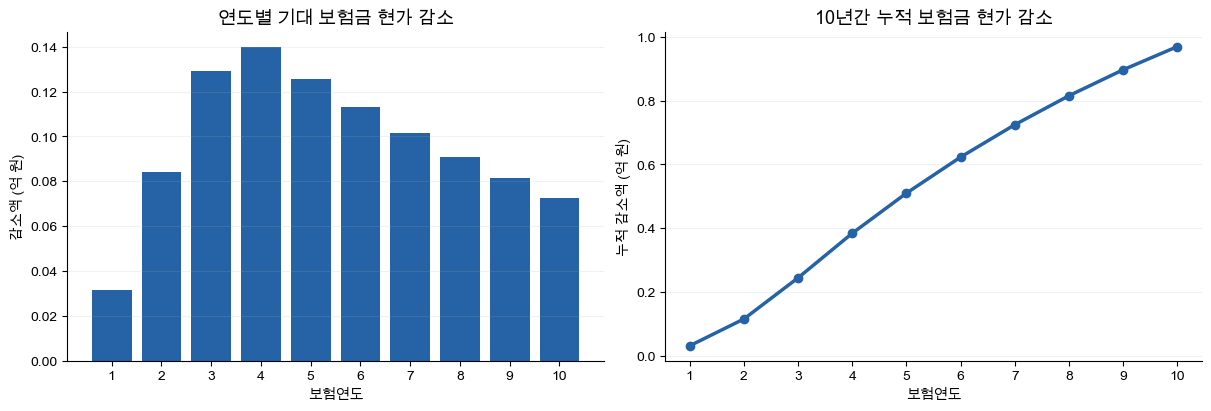

In [5]:
# 그래프 1. 같은 집단의 10년 변화: 연간 감소액과 누적 감소액
L=base['low']['monthly']; H=base['high']['monthly']
annual=pd.DataFrame([{'연도':y,
 '저확산_사망':L.loc[L['연도']==y,'월_기대사망'].sum(),
 '고확산_사망':H.loc[H['연도']==y,'월_기대사망'].sum(),
 '저확산_PV억원':L.loc[L['연도']==y,'월_보험금_현가_원'].sum()/1e8,
 '고확산_PV억원':H.loc[H['연도']==y,'월_보험금_현가_원'].sum()/1e8} for y in range(1,11)])
annual['연간_감소액억원']=annual['저확산_PV억원']-annual['고확산_PV억원']
annual['누적_감소액억원']=annual['연간_감소액억원'].cumsum()
fig,ax=plt.subplots(1,2,figsize=(12,4),layout='constrained')
ax[0].bar(annual['연도'],annual['연간_감소액억원'],color=BLUE)
ax[0].set(title='연도별 기대 보험금 현가 감소',xlabel='보험연도',ylabel='감소액 (억 원)')
ax[1].plot(annual['연도'],annual['누적_감소액억원'],marker='o',color=BLUE,lw=2.5)
ax[1].set(title='10년간 누적 보험금 현가 감소',xlabel='보험연도',ylabel='누적 감소액 (억 원)')
for a in ax: a.grid(axis='y',alpha=.17);a.set_xticks(range(1,11))
plt.show()

**그래프 해석:** 초반에는 새 치료 시작자가 쌓이므로 연도별 절감액이 커지지만, **최초 시작 뒤 3년이 지나면 효과가 끝난다**는 설정과 미시작자 감소 때문에 연도별 증가세가 약해진다. 누적 절감액이 계속 올라가는 이유는 각 연도의 절감액이 양수이기 때문이다. 이런 그래프의 모양까지 **3년 효과 가정의 산물**이지 실제 한국의 10년 추이를 관찰한 것이 아니다.

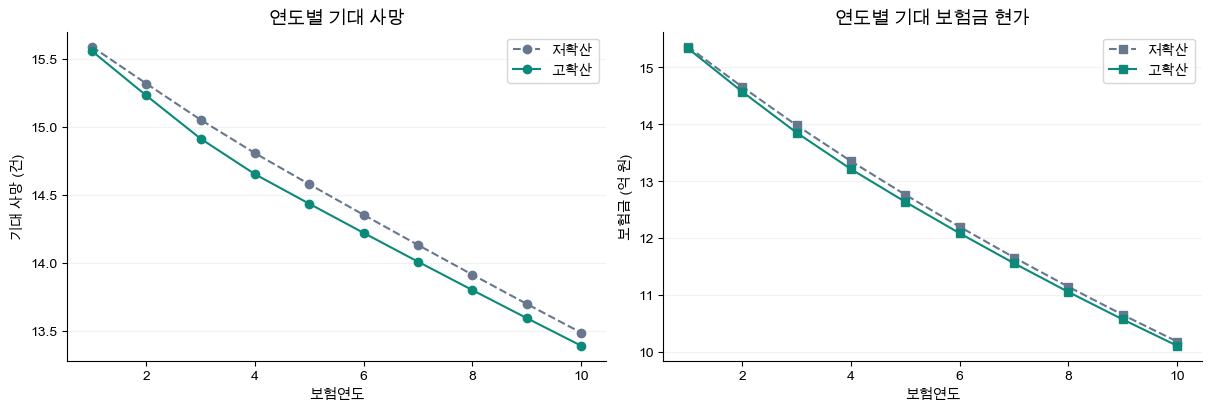

In [6]:
# 그래프 2. 기대 사망과 기대 보험금을 저확산/고확산 두 경로로 비교
fig,ax=plt.subplots(1,2,figsize=(12,4),layout='constrained')
x=annual['연도']
for name,col,line in [('저확산','저확산_사망',GREY),('고확산','고확산_사망',GREEN)]:
 ax[0].plot(x,annual[col],label=name,color=line,ls='--' if name=='저확산' else '-',marker='o')
for name,col,line in [('저확산','저확산_PV억원',GREY),('고확산','고확산_PV억원',GREEN)]:
 ax[1].plot(x,annual[col],label=name,color=line,ls='--' if name=='저확산' else '-',marker='s')
ax[0].set(title='연도별 기대 사망',xlabel='보험연도',ylabel='기대 사망 (건)')
ax[1].set(title='연도별 기대 보험금 현가',xlabel='보험연도',ylabel='보험금 (억 원)')
for a in ax:a.legend();a.grid(axis='y',alpha=.16)
plt.show()

**그래프 해석:** 두 선의 간격이 매년 그렇게 크지 않다. SELECT의 HR 0.81은 **전체 피보험자의 사망확률을 일괄 19% 줄인다는 뜻이 아니기 때문**이다. 그해 이미 치료를 시작한 사람의 일부만 효과창에 있다.

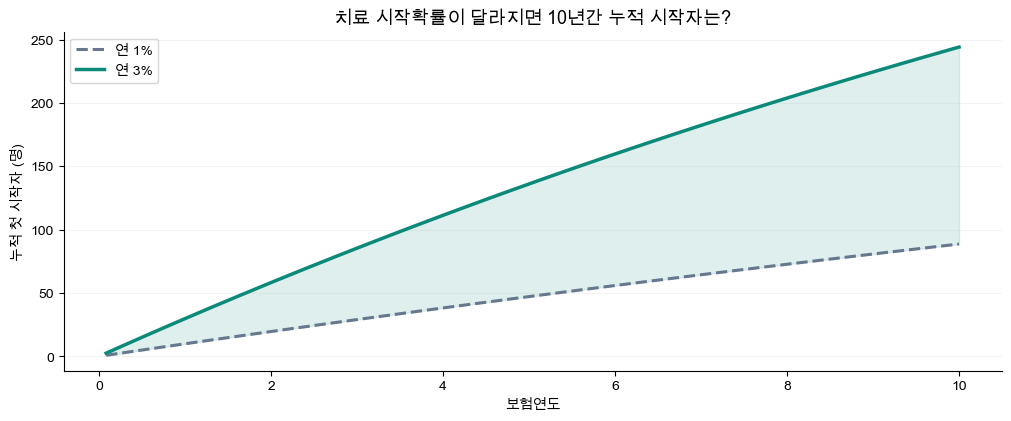

In [7]:
# 그래프 3. 누적 치료 시작자와 고확산으로 더 시작한 사람
fig,ax=plt.subplots(figsize=(10,4.1),layout='constrained')
ax.plot(L['월']/12,L['누적_시작'],color=GREY,ls='--',lw=2.2,label='연 1%')
ax.plot(H['월']/12,H['누적_시작'],color=GREEN,lw=2.5,label='연 3%')
ax.fill_between(L['월']/12,L['누적_시작'],H['누적_시작'],color=GREEN,alpha=.13)
ax.set(title='치료 시작확률이 달라지면 10년간 누적 시작자는?',xlabel='보험연도',ylabel='누적 첫 시작자 (명)')
ax.legend();ax.grid(axis='y',alpha=.15)
plt.show()

**그래프 해석:** 연간 시작확률이 3%라고 매년 30명이 새로 시작하는 것은 아니다. 시작할 수 있는 **아직 살아 있는 미시작자**가 줄어들기 때문이다. 이미 시작한 사람은 다시 첫 시작자로 세지 않는다.

## 5. 무효과까지 포함한 민감도 분석 — 핵심 결론 범위

**기준:** HR 0.81, 효과 3년, 기초 사망력 1배, 할인 3%, 연 시작확률 1%→3%. 다섯 축에서 **한 번에 하나만** 바꾼다. 파란 선은 시나리오 결과이지, 실제 관측 불확실성을 모두 포괄하는 신뢰구간은 아니다.

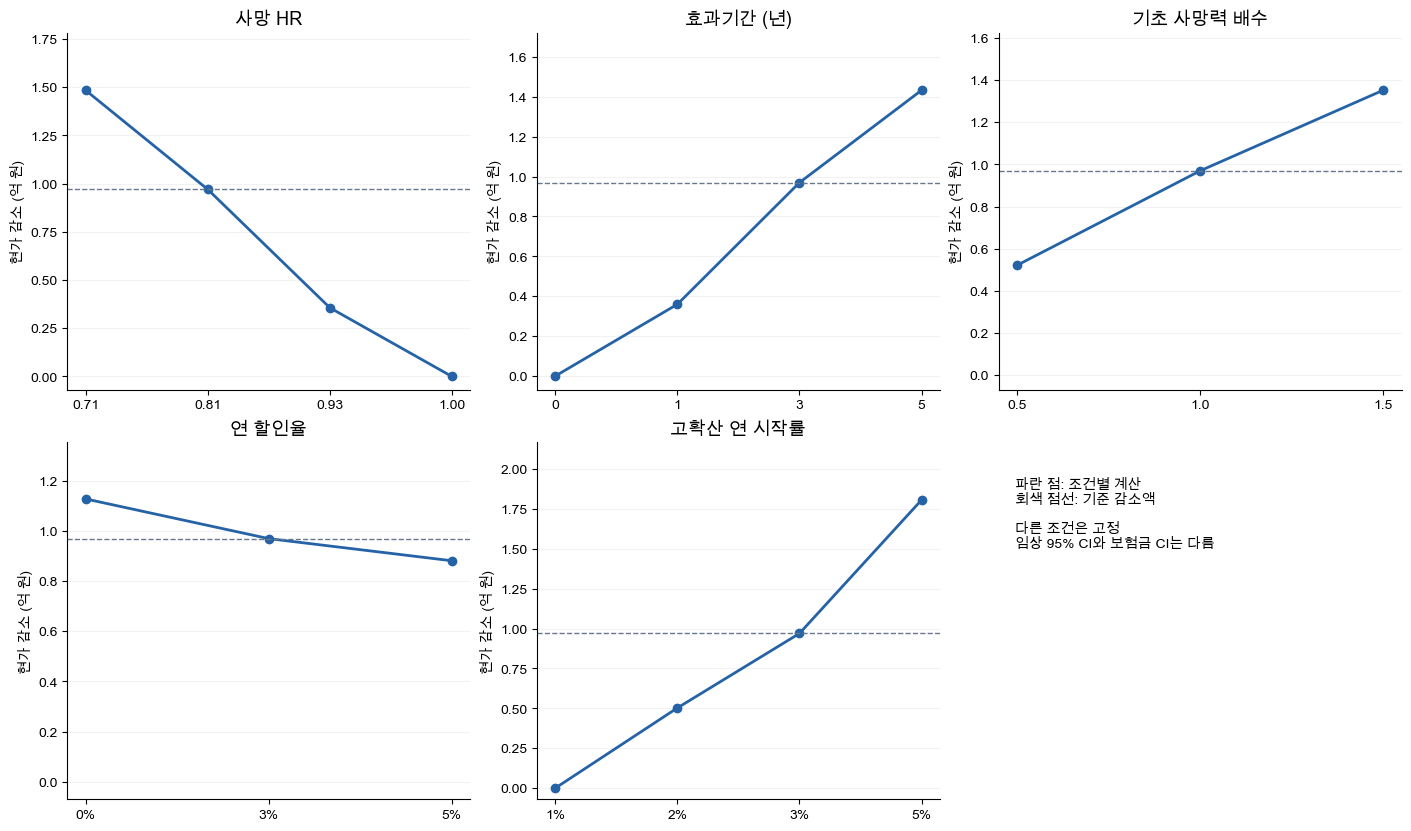

,조건,값,10년_현가감소억원
0,사망 HR,0.71,1.483245e+00
1,사망 HR,0.81,9.696186e-01
2,사망 HR,0.93,3.562751e-01
3,사망 HR,1.00,-7.629395e-14
4,효과기간 (년),0,-7.629395e-14
5,효과기간 (년),1,3.596789e-01
6,효과기간 (년),3,9.696186e-01
7,효과기간 (년),5,1.432413e+00
8,기초 사망력 배수,0.5,5.216415e-01
9,기초 사망력 배수,1.0,9.696186e-01


In [8]:
cases=[
('사망 HR',[.71,.81,.93,1],lambda x:{'hr':x},lambda x:f'{x:.2f}'),
('효과기간 (년)',[0,1,3,5],lambda x:{'effect_m':int(x*12)},lambda x:f'{x}'),
('기초 사망력 배수',[.5,1,1.5],lambda x:{'mu':MU*x},lambda x:f'{x:.1f}'),
('연 할인율',[0,.03,.05],lambda x:{'discount':x},lambda x:f'{x*100:.0f}%'),
('고확산 연 시작률',[.01,.02,.03,.05],lambda x:{'high':x},lambda x:f'{x*100:.0f}%')]
fig,axs=plt.subplots(2,3,figsize=(14,8.2),layout='constrained')
rows=[]
for ax,(title,vals,fun,fmt) in zip(axs.flat,cases):
    ys=[]
    for v in vals:
        r=contrast(**fun(v))
        ys.append(r['pv_saving']/1e8)
        rows.append({'조건':title,'값':fmt(v),'10년_현가감소억원':r['pv_saving']/1e8})
    ax.plot(range(len(vals)),ys,marker='o',color=BLUE,lw=2)
    ax.axhline(base['pv_saving']/1e8,color=GREY,ls='--',lw=1)
    ax.set(title=title,ylabel='현가 감소 (억 원)',xticks=list(range(len(vals))),xticklabels=[fmt(v) for v in vals],ylim=(-.07,max(ys)*1.2))
    ax.grid(axis='y',alpha=.16)
axs[1,2].axis('off')
axs[1,2].text(.04,.9,'파란 점: 조건별 계산\n회색 점선: 기준 감소액\n\n다른 조건은 고정\n임상 95% CI와 보험금 CI는 다름',va='top')
plt.show()
sens=pd.DataFrame(rows)
display(sens)

**해석 5가지:** 사망 HR이 1이라 치료효과가 없다면 절감액도 **0원**이다. 효과기간이 길거나 기초 사망강도가 높으면 절감액이 커진다. 할인율을 높이면 미래 보험금의 현재가치가 작아진다. 고확산 시작확률이 저확산과 같으면 비교할 변화가 없으므로 절감액이 0이다.

**결론 범위의 정의:** 기준 계약과 연 1%→3% 경로·3년 효과창·기초 위험·3% 할인 등을 고정하고, **HR만 1.00~0.71로 바꾼 값의 범위**이다. SELECT HR의 95% CI를 적용한 것과 **보험금 절감액에 대한 95% CI를 구한 것**은 다르다.

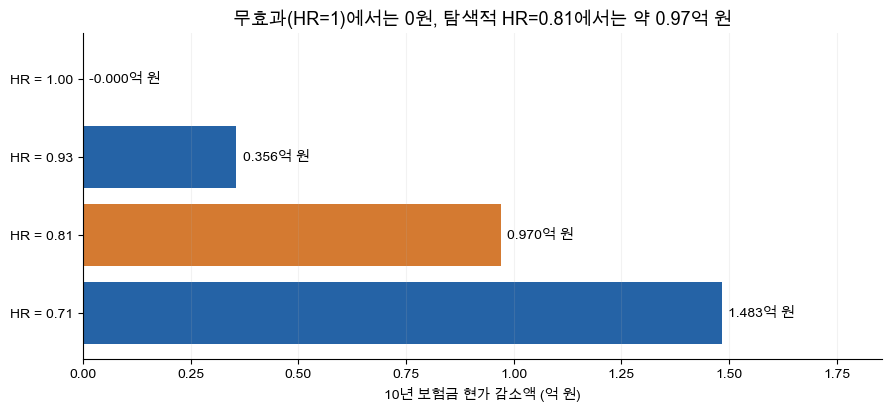

In [9]:
# 그래프 5. HR 무효과를 포함한 비교
hr_list=[1,.93,.81,.71]
res=[contrast(hr=h)['pv_saving']/1e8 for h in hr_list]
fig,ax=plt.subplots(figsize=(8.8,4),layout='constrained')
b=ax.barh([f'HR = {h:.2f}' for h in hr_list],res,color=[GREY,BLUE,ORANGE,BLUE])
ax.invert_yaxis()
for bar,v in zip(b,res):ax.text(v+.015,bar.get_y()+bar.get_height()/2,f'{v:.3f}억 원',va='center')
ax.set(xlim=(0,max(res)*1.25),xlabel='10년 보험금 현가 감소액 (억 원)',title='무효과(HR=1)에서는 0원, 탐색적 HR=0.81에서는 약 0.97억 원')
ax.grid(axis='x',alpha=.16)
plt.show()

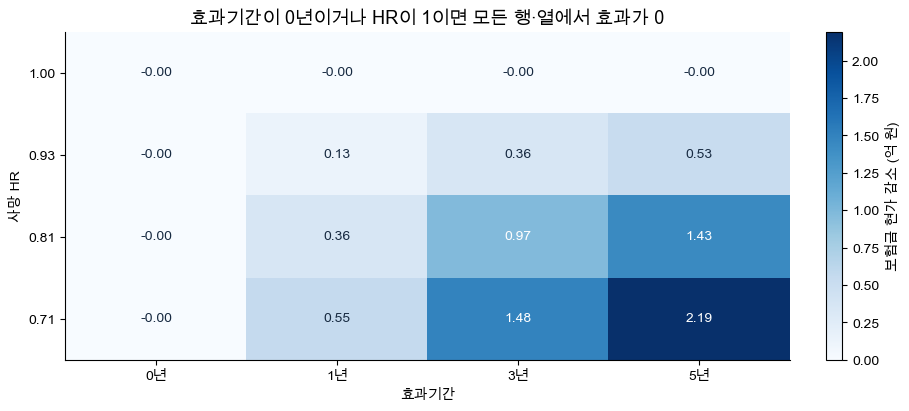

In [10]:
# 그래프 6. HR과 효과기간을 동시에 바꾸면 어떻게 되나? (가정 조합 점검, 확률적 CI 아님)
hrs=[1,.93,.81,.71]; yrs=[0,1,3,5]
heat=np.array([[contrast(hr=h,effect_m=y*12)['pv_saving']/1e8 for y in yrs] for h in hrs])
fig,ax=plt.subplots(figsize=(9,4),layout='constrained')
im=ax.imshow(heat,cmap='Blues',vmin=0,vmax=heat.max(),aspect='auto')
ax.set(xticks=range(4),xticklabels=[f'{k}년' for k in yrs],yticks=range(4),yticklabels=[f'{h:.2f}' for h in hrs],xlabel='효과기간',ylabel='사망 HR',title='효과기간이 0년이거나 HR이 1이면 모든 행·열에서 효과가 0')
for i in range(4):
 for j in range(4):ax.text(j,i,f'{heat[i,j]:.2f}',ha='center',va='center',color='white' if heat[i,j]>.9 else '#172A41')
fig.colorbar(im,ax=ax,label='보험금 현가 감소 (억 원)')
plt.show()

## 6. 국내 적용: 왜 1,000명 결과를 생보업계 전체 절감액으로 확대하면 안 되는가?

**1차 기준 추정치의 분모는 처음부터 SELECT 유사 고위험 가입자 1,000명이다.** 국내 전체 보험 가입자 1,000명이나 국내 성인 1,000명이 아니다.

국내 실제 보험 가입자 명부가 없는 상황이므로, **참고로만** 국민건강영양조사 2024의 재집계 비중을 사용해 *45~79세 가상 기존 가입자 10만 명*으로 환산한다.

- 45~79세 판별가능 일반인구 가중합 약 2,424만 명.
- 그중 SELECT 유사 조건 해당 가중합 약 6.22만 명, **11명 표본**.
- 연구팀 재집계 비율: **약 0.25675%**.
- 이 비율을 동일한 가상 가입자 10만 명에 적용하면 고위험 후보 약 257명이다. **실제 생명보험 가입자 중 257명이라는 실측 결론이 아니다.**
- 가상의 고위험 후보 전원이 위고비 미경험자이며 동일한 사망강도와 시작 경로를 갖는다는 추가 전제가 필요하다. 현실의 역선택·병력·언더라이팅 차이는 미반영.

**이 국내 환산값은 부록 성격이다. 발표 본문의 핵심 결과를 임상 1,000명 모형과 합산하지 않는다.**

In [11]:
# 국내 가상 10만 명 환산. 주 계산과 다른 분모; 일반인구 가중비율을 보험 가입자에 옮긴다는 가정.
KNHANES_SHARE=62238.568315/24240644.983522
N_100K_SELECT=100_000*KNHANES_SHARE
korea=contrast(n=N_100K_SELECT)
display(pd.DataFrame([
 {'분모':'SELECT 유사 가상 가입자 1,000명','효과 적용 후보(명)':1000,'추가 시작(명)':base['delta_starts'],'기대 사망 감소(건)':base['avoided_deaths'],'PV 감소(만 원)':base['pv_saving']/1e4},
 {'분모':'45~79세 가상 가입자 10만명 / 인구비중 이전','효과 적용 후보(명)':N_100K_SELECT,'추가 시작(명)':korea['delta_starts'],'기대 사망 감소(건)':korea['avoided_deaths'],'PV 감소(만 원)':korea['pv_saving']/1e4}]).round(3))
print('주의: 국내 보험사 관측값이 아닌 조건부 규모 환산입니다.')

,분모,효과 적용 후보(명),추가 시작(명),기대 사망 감소(건),PV 감소(만 원)
0,"SELECT 유사 가상 가입자 1,000명",1000.000,155.442,1.128,9696.186
1,45~79세 가상 가입자 10만명 / 인구비중 이전,256.753,39.910,0.290,2489.524


주의: 국내 보험사 관측값이 아닌 조건부 규모 환산입니다.


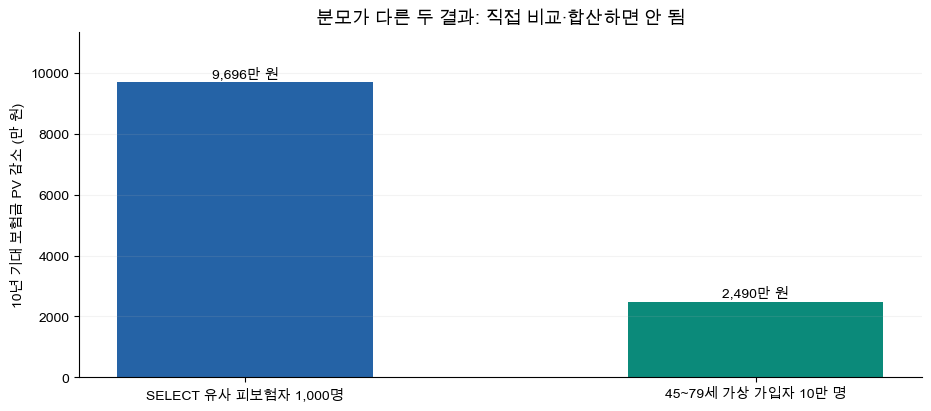

In [12]:
# 그래프 7. 분모가 다른 수치는 더해서는 안 된다
fig,ax=plt.subplots(figsize=(9.2,4),layout='constrained')
vals=[base['pv_saving']/1e4,korea['pv_saving']/1e4]
bars=ax.bar(['SELECT 유사 피보험자 1,000명','45~79세 가상 가입자 10만 명'],vals,color=[BLUE,GREEN],width=.5)
for b,v in zip(bars,vals):ax.text(b.get_x()+b.get_width()/2,v+150,f'{v:,.0f}만 원',ha='center',weight='bold')
ax.set(title='분모가 다른 두 결과: 직접 비교·합산하면 안 됨',ylabel='10년 기대 보험금 PV 감소 (만 원)',ylim=(0,max(vals)*1.17))
ax.grid(axis='y',alpha=.15)
plt.show()

## 7. 검산 — 수학적으로 제대로 계산했는가?

| 검산 질문 | 왜 필요한가? |
|---|---|
| 시작률이 같으면 효과 0인가? | 비교 대상이 같으면 차이가 0이어야 한다 |
| HR=1 또는 효과기간=0이면 0인가? | 사망위험이 달라지지 않으면 절감액이 없어야 한다 |
| 매월 살아 있는 사람 + 그 달 죽은 사람 = 전월 생존자? | 인구가 사라지거나 두 번 세어지면 안 된다 |
| 할인율=0이면 현재가치 차이=명목 차이? | 할인 공식이 제대로 작동하는지 검증한다 |
| 1,000명→2,000명으로 바꾸면 금액 2배인가? | 선형 기대값 집계인지 검증한다 |
| SELECT 원본 결과를 재현했는가? | 기준이 임의로 바뀌지 않았는지 확인한다 |

이 검산들은 **프로그램의 일관성**만 확인한다. **국내에서 1%·3%가 맞다거나 효과가 정확히 36개월이라는 사실을 검증한 것은 아니다.**

In [13]:
checks={
'저확산=고확산이면 차이 0':abs(contrast(high=.01)['pv_saving'])<1e-5,
'HR=1이면 차이 0':abs(contrast(hr=1)['pv_saving'])<1e-5,
'효과기간 0이면 차이 0':abs(contrast(effect_m=0)['pv_saving'])<1e-5,
'할인 0이면 명목과 현가 동일':abs(contrast(discount=0)['pv_saving']-base['nominal_saving'])<1e-5,
'규모 2배이면 차이 2배':abs(contrast(n=2000)['pv_saving']/base['pv_saving']-2)<1e-9,
'월 인원 보존':abs(base['low']['deaths']+base['low']['survivors']-1000)<1e-7,
'원형 기준 9,696만원 재현':abs(base['pv_saving']-96961864)<5,
'연도별 현가 합계 일치':abs(annual['연간_감소액억원'].sum()*1e8-base['pv_saving'])<1e-5}
assert all(checks.values())
display(pd.DataFrame([{'점검':k,'결과':'통과' if v else '실패'} for k,v in checks.items()]))

,점검,결과
0,저확산=고확산이면 차이 0,통과
1,HR=1이면 차이 0,통과
2,효과기간 0이면 차이 0,통과
3,할인 0이면 명목과 현가 동일,통과
4,규모 2배이면 차이 2배,통과
5,월 인원 보존,통과
6,"원형 기준 9,696만원 재현",통과
7,연도별 현가 합계 일치,통과


## 8. 결과를 발표할 때의 문장과 반론

> **발표용 결론:** SELECT 임상시험의 기초 사망강도와 탐색적 전체 사망 HR 0.81을 사용해, 국내에서 적용을 검토할 수 있는 고위험 가상 정기사망보장 가입자 1,000명의 10년 사망보험금 변화를 추정했다. 연간 첫 치료 시작확률이 1%에서 3%로 높아지고 최초 시작 후 3년 동안 상대 사망강도 감소가 유지된다고 가정하면, 10년 기대 사망은 약 **1.13건**, 사망보험금 현재가치는 약 **9,696만 원** 감소한다. 같은 조건에서 **사망효과가 없는 HR=1의 경우 절감액은 0원**이며, HR=0.71까지의 단일변수 점검 범위는 **0~1.48억 원**이다. **이것은 실제 국내 보험사의 절감액도, 보험사의 순이익도 아니라 공개 임상자료와 계약·확산 가정을 연결한 조건부 추정치**다.

**예상 반론에 대한 답변**

1. *왜 10년인데 임상은 약 3.3년인가?* → 만기가 10년인 것은 보험계약의 설정이며, 효과를 10년 유지한다고 주장하지 않았다. 최초 시작 후 3년 효과창도 연구 가정이며, 이후 HR=1을 적용해 만기까지 생존자를 추적했다.
2. *3%가 한국의 실제 시작률인가?* → 아니다. CBO의 해외 AOM 전망은 외부 타당성 참고일 뿐, 1%→3% 비교는 연구 설계조건이다. 한국 고위험 피보험자 대상 신규 시작률을 관측했다고 주장하지 않는다.
3. *HR=0.81이 사망 19% 감소 확정이라는 뜻인가?* → 시간별 사망강도 상대값이다. 전체 사망의 결과는 다중검정 체계상 탐색적이다. HR=1 무효과도 포함했다.
4. *왜 전체 국민으로 확대하지 않는가?* → SELECT 환자 조건과 일반 비만 인구가 다르고, 보험사 계약 구성과 과거 사용력이 없으므로 실제 시장 금액으로 확대할 수 없다.
5. *특약 상품이 돈을 번다는 뜻인가?* → 아니다. 이 분석은 **기존 사망보험금 기대지급액**만 다룬다. 특약 도입의 추가 시작 효과 B·특약 청구·사업비·보험료·준비금은 별도다.

## 9. 한 문장 정리

**치료 확산이 실제로 일어나고 SELECT의 사망위험 감소가 해당 피보험자에게도 유지된다면 기존 정기사망보장의 기대지급액은 감소한다. 그 규모는 치료효과·기초위험·시작경로·효과기간에 달려 있으며, 여기서 제시한 9,696만 원은 조건을 명확히 공개한 연구용 추정치다.**

## 부록 · 전체 출처·데이터·단위

- [SELECT 논문](https://doi.org/10.1056/NEJMoa2307563) (Lincoff et al., NEJM 2023)
- [CADTH / NCBI Table 19](https://www.ncbi.nlm.nih.gov/books/NBK619926/table/tr8269868382084182_ch01_t19/?report=objectonly) (사망건수·관찰인년·HR)
- [사망과 COVID-19 세부분석 (JACC 2024)](https://pubmed.ncbi.nlm.nih.gov/39217559/) (보조 임상정보)
- [Nanna 등 (2025)](https://pmc.ncbi.nlm.nih.gov/articles/PMC12046440/) (10년 집단 추정 방법론; 입력값 직접 채택 안 함)
- [CBO(2024) 비만치료제 보장 확대 추정](https://www.cbo.gov/publication/60816) (해외 시작률 정책 예측; 국내 값 아님)
- [국민건강영양조사](https://knhanes.kdca.go.kr/) (국내 SELECT 유사 대리집단 기존 재집계)
- [2024 국내 생명표](https://mods.go.kr/board.es?act=view&bid=208&list_no=439533&mid=a10301010000) (대조 자료, 본 기준위험 미사용)

**엄밀한 한계:** 일정 사망강도 가정, 10년 시간경과에 따른 연령별 위험 변화 없음, 임상시험 대상과 국내 피보험자 차이, 전체 사망 HR의 탐색성, 위고비 시작 후 36개월 효과창 가정, 미관측 최초 시작률, 계약 해지 미반영, 코로나19 시대 사건 포함 가능성, 경쟁사건·약물중단·재개의 임상 HR 이중 반영 문제. 의료적 효과·실제 사망보험금·이익의 실증 검증이 아니다.